# Example: KMT-2022-BLG-1551 — a high-magnification event with central and planetary caustics

This is one of a series of example notebooks that run lenscape's map pipeline, with its default settings, on
published planetary events. Together they show both how well the method works and where it reaches its limits.
`example_kb200202` and `example_kb230466` are the others from the same paper.

**The event.** KMT-2022-BLG-1551 (Han et al. 2026, *Four Cold Super-Jupiters Revealed by Extended and Complex
Microlensing Signals*, arXiv:2601.13450) peaked in July 2022 at a very high magnification (*A* ≈ 425 in the published
model). The anomaly spans about a third of the event timescale and has four features: a brief bump at HJD′ ≈ 9776.1
(*t*₁), a smoother one at 9779.5 (*t*₂) and a caustic-crossing pair at 9781.3 and 9781.9 (*t*₃, *t*₄), where
HJD′ = HJD − 2450000. The planet produces a central caustic and two planetary caustics; the source grazes the tip of
one planetary caustic, passes between the caustics and then crosses the central one. Han et al. report a unique
solution with *s* = 0.884, *q* = 5.26 × 10⁻³ and *t*ₑ = 19.3 d (their Table 3).

Compared with the other two examples, the planet here lies inside the Einstein ring (*s* < 1), the peak is covered by
a dense run of points, and the map has two valleys, one on each side of *s* = 1.

**What this notebook does.**

1. It loads the public photometry of the three KMTNet sites (1014 points).
2. It loads the map on the lattice of Han et al.'s Fig. 2 (57 × 60 points).
3. It densifies the map to 2× everywhere and to 4× in the central region.
4. It compares the maps with each other and with the published map.
5. It describes the planned zoom on the valley of the published solution (Section 6).
6. It shows the light curves of the alternative solutions (Section 7).
7. It looks at what the maps get wrong (Section 8).

**Runtime.** The 1×, 2× and central 4× maps took 212, 96 and 122 minutes on a 14-core Intel Core i5-13500
(20 threads), the zoom of Section 6 is not computed yet. All maps are stored in `data/`, so the notebook
runs in a minute or two by default. Set `RECOMPUTE = True` to recompute them.

## 0. Setup

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.optimize import minimize
import lenscape
from lenscape import figures

RECOMPUTE = False              # True: compute all maps again (7.2 h on a 20-thread desktop); False: only what data/ lacks
LOGFILE = os.environ.get("LENSCAPE_LOG")          # progress of long runs is also appended here if set


def log(msg):
    print(msg, flush=True)
    if LOGFILE:
        with open(LOGFILE, "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")

print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/kb221551_photometry.csv` holds the public pySIS difference-imaging photometry from the KMTNet event page: field
BLG15, *I* band, HJD′ 9740–9830, from KMTNet Chile (KMTC15), South Africa (KMTS15) and Australia (KMTA15). It has
one row per measurement:

| column | meaning |
|---|---|
| `set` | data set (`KMTC15`, `KMTS15`, `KMTA15`) |
| `t` | HJD − 2450000 |
| `flux` | pySIS difference flux Δflux (arbitrary zero point; in these files it *decreases* as the star brightens) |
| `flux_err` | its error, rescaled (see below) |

The error bars are rescaled with the usual error model (Yee et al. 2012): σ′ = *k* √(σ² + σ_min²) in magnitudes, with
σ_min = 0.020, 0.020 and 0.010 for KMTC, KMTS and KMTA as in Han et al. (Table 2), and one *k* per data set chosen so
that the best fit has χ²/N = 1 for each (*k* = 1.52, 1.85 and 2.72). Two KMTA points more than 5σ off the best fit
were removed. Han et al. used their own re-reduction of the same images (*k* = 1.22, 1.29, 1.51) and also 32 points
from follow-up observations with the LCOS telescope shortly after the peak, which are not public. KMTC was under
maintenance during the anomaly: between HJD′ 9774 and 9784 only KMTS and KMTA observed.

In [2]:
rows = np.genfromtxt("data/kb221551_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
SETS = ["KMTC15", "KMTS15", "KMTA15"]
# pySIS Delta_flux falls as the star brightens; flip the sign so that brighter is up. The fit does not care: the
# source and blend fluxes change sign, chi2 is identical.
data = lenscape.Data.from_sets({n: (rows["t"][rows["set"] == n], -rows["flux"][rows["set"] == n],
                                    rows["flux_err"][rows["set"] == n]) for n in SETS})
data

Data(1014 points, t 9740.29 .. 9829.98, sets {'KMTC15': 430, 'KMTS15': 334, 'KMTA15': 250})

## 2. The best fit

A map needs one good model as its starting point, given as `(t0, u0, tE, log10 s, log10 q, alpha, log10 rho)`. This
one was fitted to these data from the published parameters (`lenscape.fit_full`). It agrees with Table 3 of Han et
al.:

| | *s* | *q* (10⁻³) | *t*ₑ (d) | ρ (10⁻³) | *t*₀ (HJD′) | \|*u*₀\| (10⁻³) |
|---|---|---|---|---|---|---|
| Han et al. (2026) | 0.8840 ± 0.0027 | 5.26 ± 0.57 | 19.31 ± 0.65 | 3.13 ± 0.29 | 9781.3238 ± 0.0027 | 0.71 ± 0.29 |
| these data | 0.881 | 5.29 | 18.92 | 2.78 | 9781.326 | 0.89 |

The trajectory angle α and the sign of *u*₀ are not compared because the two codes use different conventions. The
source size ρ is 1.2σ below the published value; the LCOS points, which these data lack, may account for part of
the difference.

The plot shows all three data sets on the flux scale of KMTC15. Each set is aligned with the source and blend fluxes
of the best fit, so the models of other solutions in later plots are drawn for KMTC15 only. The residual panels use
each solution's own fluxes and are exact. The top panel has a logarithmic flux axis, because the flux changes by a
factor of a few hundred over the event.

chi2 = 1014.0 for 1014 points;  s = 0.8813, q = 5.29e-3, tE = 18.92 d, rho = 2.78e-3


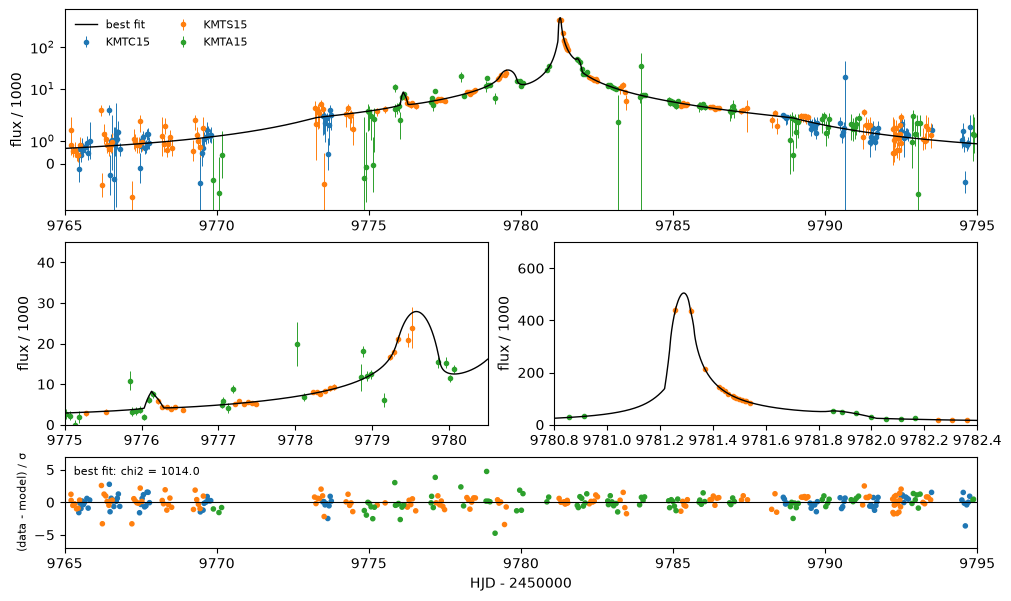

In [3]:
best = np.array([9781.326413313225, 0.0008860115242737657, 18.917910145980382, -0.054867763836839535,
                 -2.276866979834819, 2.7125718499917837, -2.5557349640730447])
be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
chi2_best = lenscape.model.chi2(be, best, data)
print(f"chi2 = {chi2_best:.1f} for {len(data)} points;  s = {10 ** best[3]:.4f}, q = {10 ** best[4] * 1e3:.2f}e-3, "
      f"tE = {best[2]:.2f} d, rho = {10 ** best[6] * 1e3:.2f}e-3")


def plot_flux(sols, window=(9765, 9795), zooms=((9775.0, 9780.5), (9780.8, 9782.4)), ylims=((0, 45), (0, 700)), d=None):
    # data of all sets on the KMTC15 flux scale (aligned with the best fit), the KMTC15 model of each solution, two
    # zooms on the anomaly (t1 and t2; the caustic pair t3 and t4, y range cut so that the data stay visible) and one
    # panel of normalised residuals per solution (each with its own fluxes); the top panel has a symmetric-log axis
    d = data if d is None else d
    styles = ["-", ":", "--", "-."]
    fs0, fb0 = lenscape.model.fluxes(lenscape.model.magnification(be, best, d), d)
    fig = plt.figure(figsize=(10, 4.8 + 1.1 * len(sols)), constrained_layout=True)
    gs = fig.add_gridspec(2 + len(sols), 2, height_ratios=[2.2, 2.0] + [1] * len(sols))
    top = fig.add_subplot(gs[0, :]); zax = [fig.add_subplot(gs[1, k]) for k in range(2)]
    for ax, (a, b) in zip([top] + zax, [window] + list(zooms)):
        for k, name in enumerate(d.names):
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            f = (d.f[m] - fb0[k]) / fs0[k] * fs0[0] + fb0[0]
            ax.errorbar(d.t[m], f / 1e3, d.e[m] * abs(fs0[0] / fs0[k]) / 1e3, fmt="o", ms=3, lw=0.7, color=f"C{k}",
                        label=name if ax is top else None, zorder=2)
        tt = np.linspace(a, b, 4000)
        for (name, p), ls in zip(sols.items(), styles):
            fs, fb = lenscape.model.fluxes(lenscape.model.magnification(be, p, d), d)
            Am = be.lc(lenscape.model.clamp(p)[0], tt)
            ax.plot(tt, (fs[0] * Am + fb[0]) / 1e3, ls, color="k", lw=1, label=name if ax is top else None, zorder=3)
        ax.set_xlim(a, b); ax.set_ylabel("flux / 1000")
    for ax, yl in zip(zax, ylims):
        ax.set_ylim(*yl)
    top.set_yscale("symlog", linthresh=2); top.set_ylim(-2, 800)
    top.legend(fontsize=8, frameon=False, ncol=2, loc="upper left")
    for k, (name, p) in enumerate(sols.items()):
        ax = fig.add_subplot(gs[2 + k, :], sharex=top)
        r = lenscape.model.residuals(be, p, d)
        m = (d.t > window[0]) & (d.t < window[1])
        ax.scatter(d.t[m], r[m], s=9, c=[f"C{i}" for i in d.idx[m]]); ax.axhline(0, color="k", lw=0.8)
        ax.set_ylim(-7, 7); ax.set_ylabel("(data - model) / σ", fontsize=8)
        ax.text(0.01, 0.8, f"{name}: chi2 = {np.sum(r ** 2):.1f}", transform=ax.transAxes, fontsize=8)
    ax.set_xlabel("HJD - 2450000")
    return fig

plot_flux({"best fit": best});

The left zoom shows *t*₁ and *t*₂, covered by KMTA and KMTS. The right zoom shows the peak: KMTS's automatic follow-up
mode (about 3.5 points per hour) covers the decline after the caustic crossing *t*₃ at HJD′ 9781.3, and KMTA covers
the weaker *t*₄.

For later comparison, here is the **single-lens floor**: the χ² of the best point-lens model (with a finite source),
measured against the binary best fit. Points of a map with Δχ² near this value are no better than having no planet
at all.

In [4]:
def chi2_1l1s(x):
    A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]), 10 ** x[3], data.t, 0.0)
    fs, fb = lenscape.model.fluxes(A, data)
    return float((((data.f - fs[data.idx] * A - fb[data.idx]) / data.e) ** 2).sum())

chi2_single = min(minimize(chi2_1l1s, [best[0], u0, best[2], -3.0], method="Nelder-Mead",
                           options=dict(maxfev=4000, adaptive=True)).fun for u0 in (0.001, 0.01, 0.03, 0.1, 0.3))
floor = chi2_single - chi2_best
print(f"single-lens floor: Delta chi2 = {floor:.0f}")

single-lens floor: Delta chi2 = 971


The floor is about 970, the highest of the three examples: the planet changes the light curve over several days
around a well-covered peak.

## 3. Stage 1: the lattice of the published map

These are the axes of Han et al.'s Fig. 2, measured from the figure, plus a margin of two points on each side. There
are 57 points in log *s* from −0.800 to +0.855 (step 0.0296) and 60 points in log *q* from −3.63 to +0.09 (step
0.0631). `lenscape.lattice` runs its five stages (seed grid, cell fits, lattice-point fits, neighbour refinement,
outlier recalculation); `06_maps` explains each. **Runtime: 212 minutes** (20 threads).

In [5]:
dls, dlq = 0.02955, 0.0631
logs1 = -0.8000 + dls * np.arange(57)
logq1 = -3.6305 + dlq * np.arange(60)
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")

def run_or_load(name, compute):
    # data/kb221551_map_NAME.npz: computed (and saved) if missing or RECOMPUTE, else loaded
    path = f"data/kb221551_map_{name}.npz"
    if RECOMPUTE or not os.path.exists(path):
        log(f"computing map {name}")
        m = compute()
        np.savez_compressed(path, **{k: m[k] for k in KEYS})
        log(f"map {name}: {m['chi2'].shape}, {m['wall'] / 60:.1f} min, lowest chi2 {np.nanmin(m['chi2']):.2f}")
        return m
    return dict(np.load(path))

map1 = run_or_load("1x", lambda: lenscape.lattice(data, logs1, logq1, best=best, log=log))
print(f"{map1['chi2'].shape} points, wall time {map1['wall'] / 60:.0f} min")

(57, 60) points, wall time 212 min


## 4. Stages 2 and 3: 2× everywhere, 4× in the central region

`lenscape.maps.densify` fits every point of a finer lattice from the nearest known solutions. It then refines the
map with the same neighbour and outlier stages as `lattice`. The 2× map covers the whole lattice (113 × 119 points,
**96 minutes**). The 4× map covers only the central region −0.25 ≤ log *s* ≤ 0.25, −3.5 ≤ log *q* ≤ −1.0: the points
of the full 4× lattice inside that box (68 × 158 points, a fifth of the full 4× lattice, **122 minutes**). The box
holds both valleys and every point of the 1× map with Δχ² < 90.

In [6]:
map2 = run_or_load("2x", lambda: lenscape.maps.densify(
    [map1], data, logs1[0] + dls / 2 * np.arange(113), logq1[0] + dlq / 2 * np.arange(119), best=best, log=log))
map4 = run_or_load("4x", lambda: lenscape.maps.densify(       # central region: points 75..142 x 9..166 of the 4x lattice
    [map2], data, logs1[0] + dls / 4 * np.arange(75, 143), logq1[0] + dlq / 4 * np.arange(9, 167), best=best, log=log))
MAPS = [("1x", map1), ("2x", map2)]
ref = min(chi2_best, np.nanmin(map2["chi2"]), np.nanmin(map4["chi2"]))
for name, m in MAPS + [("4x box", map4)]:
    i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
    print(f"{name:6s}: {m['chi2'].shape[0]:3d} x {m['chi2'].shape[1]:3d} points, wall time {m['wall'] / 60:3.0f} min, "
          f"minimum {m['chi2'][i, j] - chi2_best:+.2f} against the best fit at log s = {m['logs'][i]:.4f}, "
          f"log q = {m['logq'][j]:.3f}")

1x    :  57 x  60 points, wall time 212 min, minimum +17.06 against the best fit at log s = -0.0613, log q = -2.242
2x    : 113 x 119 points, wall time  96 min, minimum +5.43 against the best fit at log s = -0.0465, log q = -2.621
4x box:  68 x 158 points, wall time 122 min, minimum +1.60 against the best fit at log s = -0.0539, log q = -2.290


## 5. The maps

All maps are drawn against the same reference χ², the lowest of the best fit and the map minima, with a logarithmic
colour scale up to Δχ² = 1000, just above the single-lens floor. The third panel is the central 4× box.

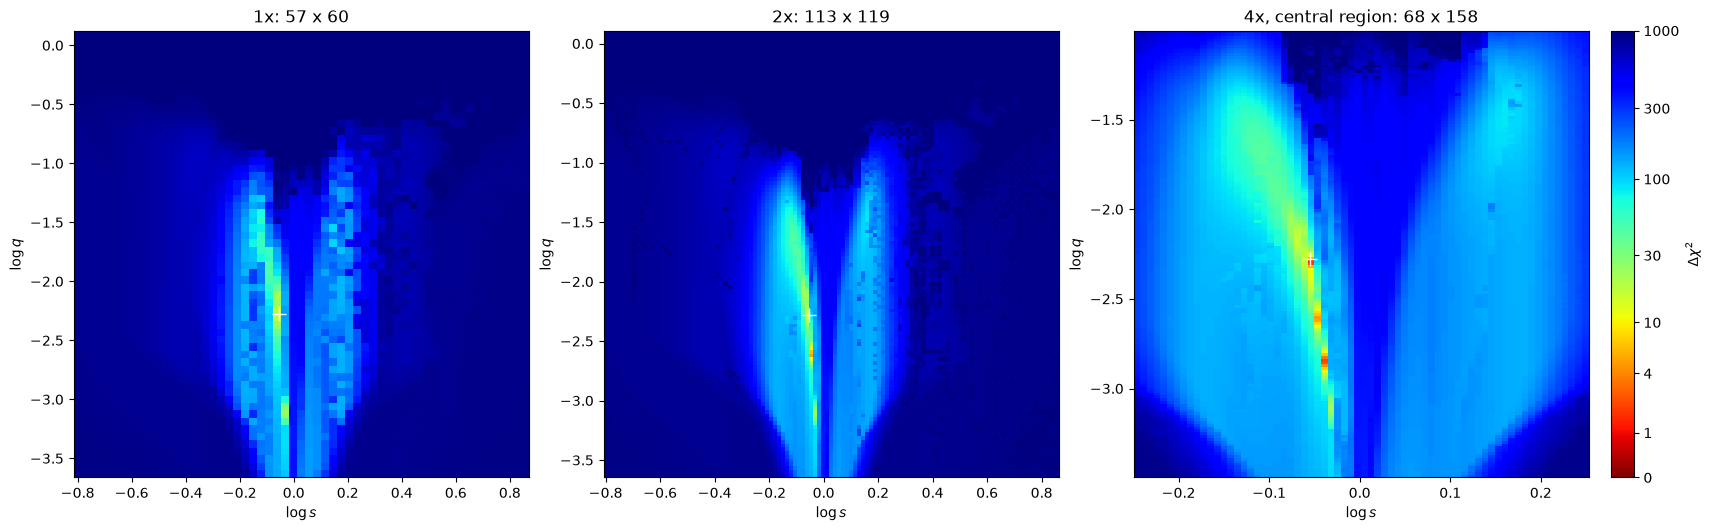

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(17, 5.2), constrained_layout=True)
for ax, (name, m) in zip(axs, MAPS + [("4x, central region", map4)]):
    figures.plot_map(m, ax=ax, vmax=1000, chi2_ref=ref, colorbar=(ax is axs[2]))
    ax.plot(best[3], best[4], "w+", ms=10)
    ax.set_title(f"{name}: {m['chi2'].shape[0]} x {m['chi2'].shape[1]}")

All maps show two valleys, one on each side of log *s* = 0. The **close valley** runs from log *s* ≈ −0.12 at
log *q* = −1.5 to −0.03 at log *q* = −3.4 and holds the published solution. The **wide valley** (log *s* ≈ +0.15 to
+0.18) stays 85 to 145 above the minimum. The close valley is narrower than the lattice steps. Its lowest point is
17 above the best fit at 1×, 5.4 at 2× (at log *q* = −2.62, not at the best fit's −2.28) and 1.6 at 4×, at
log *s* = −0.054, log *q* = −2.29, the 4× point next to the best fit. Even at 4× the valley floor is about one lattice
column wide and breaks up into patches; Section 6 plans a zoom on it.

**Comparison with the paper.** `data/kb221551_han2026_fig2.csv` holds the coloured cells of Han et al.'s Fig. 2, read
from the figure's vector graphics. Their bands are Δχ² ≤ *n* × (1, 4, 9, 16) with *n* = 10, white above 160. We draw
them next to our 2× map in the same bands, with no rescaling.

1x: of the 351 paper cells, same band 16 %, within one band 71 %, above 160 in our map 65 %
2x: of the 351 paper cells, same band 20 %, within one band 77 %, above 160 in our map 55 %


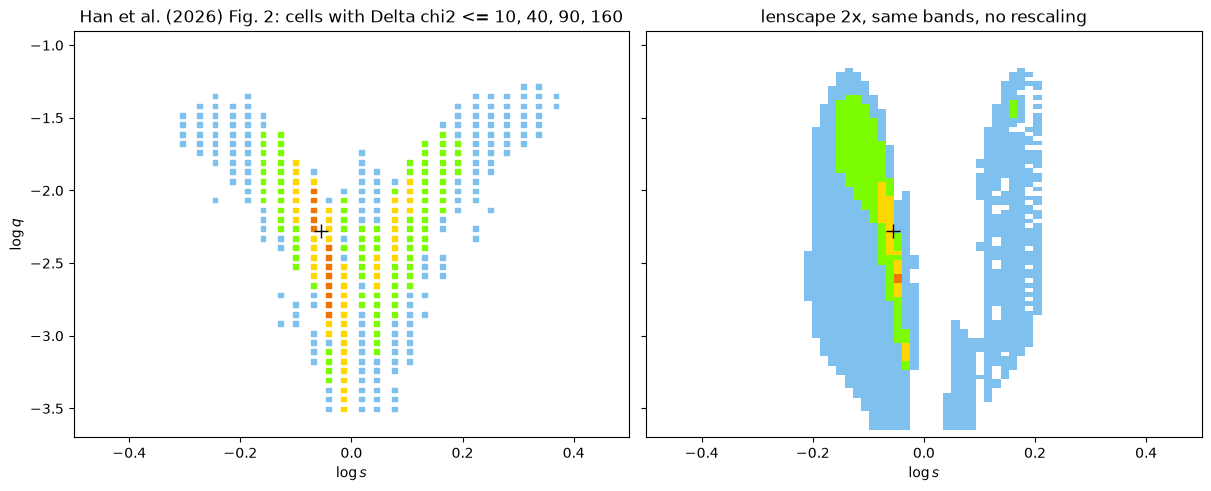

In [8]:
cells = np.genfromtxt("data/kb221551_han2026_fig2.csv", delimiter=",", names=True, skip_header=2)
edges = 10 * np.array([1, 4, 9, 16])
band_cmap = ListedColormap(["#ee7600", "gold", "lawngreen", "#7ec0ee", "white"])
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True, sharex=True, sharey=True)
o = np.argsort(-cells["band"])
axs[0].scatter(cells["log_s"][o], cells["log_q"][o], c=cells["band"][o] - 1, cmap=band_cmap, vmin=-0.5, vmax=4.5,
               marker="s", s=12)
axs[0].set_title("Han et al. (2026) Fig. 2: cells with Delta chi2 <= 10, 40, 90, 160")
band2 = np.searchsorted(edges, map2["chi2"] - ref)                       # 0..3 inside the bands, 4 above 160
axs[1].pcolormesh(map2["logs"], map2["logq"], band2.T, cmap=band_cmap, vmin=-0.5, vmax=4.5, shading="nearest")
axs[1].set_title("lenscape 2x, same bands, no rescaling")
for ax in axs:
    ax.plot(best[3], best[4], "k+", ms=10); ax.set_xlabel(r"$\log s$")
    ax.set_xlim(-0.5, 0.5); ax.set_ylim(-3.7, -0.9)
axs[0].set_ylabel(r"$\log q$")

# band of our maps at each paper cell (nearest lattice point)
for name, m in MAPS:
    i = np.round((cells["log_s"] - m["logs"][0]) / (m["logs"][1] - m["logs"][0])).astype(int)
    j = np.round((cells["log_q"] - m["logq"][0]) / (m["logq"][1] - m["logq"][0])).astype(int)
    ours = np.searchsorted(edges, m["chi2"][i, j] - ref) + 1
    print(f"{name}: of the {len(cells)} paper cells, same band {100 * np.mean(ours == cells['band']):.0f} %, within one "
          f"band {100 * np.mean(abs(ours - cells['band']) <= 1):.0f} %, above 160 in our map {100 * np.mean(ours == 5):.0f} %")

The shapes agree: both arms of the V, with the published minimum in the close one. Without rescaling, 77 % of the
paper's cells fall within one band of our 2× map. The paper's values are lower than ours: 55 % of its cells (all
≤ 160) are above 160 in our map. The same happened for KMT-2023-BLG-0466; here Han et al. also had 32 LCOS points and
their own reduction of the KMTNet images, with smaller error factors (*k* = 1.22–1.51, ours 1.52–2.72).

## 6. Zoom on the valley of the published solution

The close valley is a narrow band, tilted in (log *s*, log *q*), that even the 4× lattice (0.0074 dex in log *s*)
covers with only about one column. As for KMT-2023-BLG-0466 we compute a **zoom**: a new lattice over the box
−0.10 ≤ log *s* ≤ −0.02, −3.3 ≤ log *q* ≤ −1.8, which contains every 4× point with Δχ² < 40. First 50 × 50 points,
started from the 4× map; then 99 × 99 points, started from the 50 × 50 zoom and the 4× map. In log *s* the 99 × 99
zoom is ten times finer than the 4× map.

*The zoom maps are not computed yet; this section will show them, next to the 2× and 4× maps of the same box.*

## 7. What the alternatives look like

We pick the lowest point of the 4× map in three regions and draw its light curve next to the best fit:

* the **wide** valley (log *s* > 0.05);
* the close valley at **low *q*** (log *q* < −3), where it runs closest to log *s* = 0;
* the close valley at **high *q*** (log *q* > −1.8).

The map stores the five fitted parameters `(t0, u0, tE, alpha, log rho)` at each (*s*, *q*), and
`lenscape.fit.full_p` turns them into the seven-parameter vector.

best fit       log s = -0.055  log q = -2.277  tE =  18.9 d  Delta chi2 =  -0.0  (t1  +0.0, t2  +0.0, t3  +0.0, t4  +0.0)
wide           log s = +0.168  log q = -1.469  tE =  23.8 d  Delta chi2 =  84.9  (t1 +24.9, t2  +3.9, t3  +1.3, t4 +34.8)
close, low q   log s = -0.032  log q = -3.110  tE =  32.8 d  Delta chi2 =  22.7  (t1 +20.5, t2  -9.4, t3  +6.9, t4  +0.4)
close, high q  log s = -0.106  log q = -1.722  tE =  22.1 d  Delta chi2 =  41.1  (t1 +25.1, t2  -2.0, t3  -0.3, t4 +18.3)


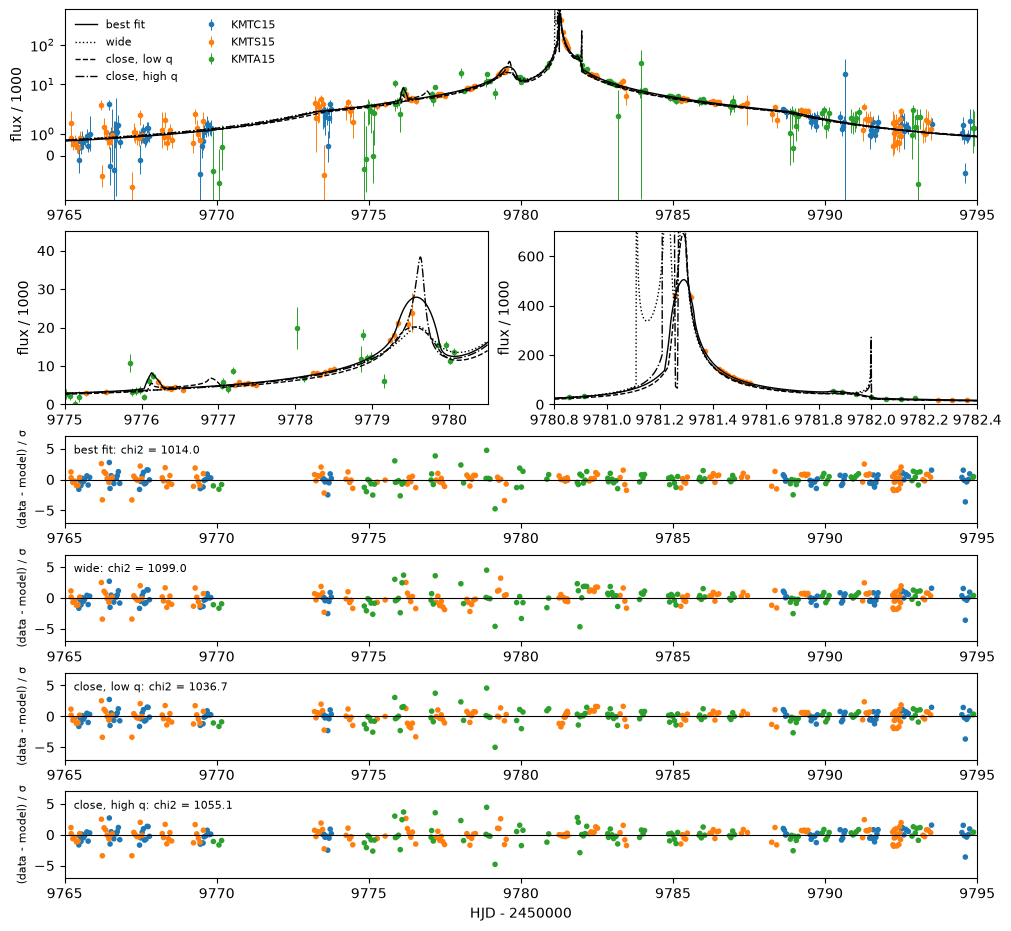

In [9]:
def lowest(m, s_range, q_range=(-9, 9)):
    si = np.where((m["logs"] > s_range[0]) & (m["logs"] < s_range[1]))[0]
    qi = np.where((m["logq"] > q_range[0]) & (m["logq"] < q_range[1]))[0]
    sub = m["chi2"][np.ix_(si, qi)]
    a, b = np.unravel_index(np.nanargmin(sub), sub.shape)
    i, j = si[a], qi[b]
    return np.array(lenscape.fit.full_p(m["pars"][i, j], m["logs"][i], m["logq"][j]))

sols = {"best fit": best, "wide": lowest(map4, (0.05, 0.5)), "close, low q": lowest(map4, (-0.5, 0.05), (-4, -3.0)),
        "close, high q": lowest(map4, (-0.5, 0.05), (-1.8, 0))}
FEATURES = {"t1": (9775.5, 9776.6), "t2": (9779.0, 9780.2), "t3": (9781.1, 9781.6), "t4": (9781.7, 9782.2)}
r_best = lenscape.model.residuals(be, best, data)
for name, p in sols.items():
    r = lenscape.model.residuals(be, p, data)
    parts = [f"{k} {np.sum((r ** 2 - r_best ** 2)[(data.t > a) & (data.t < b)]):+5.1f}" for k, (a, b) in FEATURES.items()]
    print(f"{name:14s} log s = {p[3]:+.3f}  log q = {p[4]:+.3f}  tE = {p[2]:5.1f} d  Delta chi2 = {np.sum(r ** 2) - ref:5.1f}"
          f"  (" + ", ".join(parts) + ")")
plot_flux(sols);

The brief bump at *t*₁ (HJD′ 9776.1, a handful of KMTA and KMTS points) is what only the published solution
reproduces: every alternative loses 20 to 25 in χ² there. Beyond that they fail differently:

* the **close, low-*q*** solution (Δχ² ≈ 23) fits *t*₂ even better than the best fit (by 9) but also misses *t*₃;
* the **close, high-*q*** solution (Δχ² ≈ 41) misses *t*₄ as well;
* the **wide** solution (Δχ² ≈ 85) misses *t*₁ and *t*₄ and fits the rest of the light curve worse.

All three alternatives put their sharpest caustic spikes at HJD′ 9781.1–9781.3, just before the first points on the
peak, where no data constrain them.

## 8. Limits of the maps

### 8.1 The coarse maps miss low-χ² solutions

Every point of the 1× lattice is also a point of the 2× lattice, and every 2× point inside the central box is a 4×
point. Comparing the values at these shared points shows how much each doubling found that the coarser map missed:

In [10]:
c2 = map2["chi2"][::2, ::2]
diff = map1["chi2"] - c2
for label, sel in [("Delta chi2 < 160 at 2x", c2 - ref < 160), ("all points", np.isfinite(c2))]:
    print(f"1x vs 2x, {label:22s}: {sel.sum():5d} points, 1x higher by > 1 at {100 * (diff[sel] > 1).mean():3.0f} %, "
          f"by > 10 at {100 * (diff[sel] > 10).mean():3.0f} %, lower by > 1 at {100 * (diff[sel] < -1).mean():.1f} %")
i2 = (map2["logs"] >= map4["logs"][0] - 1e-9) & (map2["logs"] <= map4["logs"][-1] + 1e-9)
j2 = (map2["logq"] >= map4["logq"][0] - 1e-9) & (map2["logq"] <= map4["logq"][-1] + 1e-9)
c2b = map2["chi2"][np.ix_(i2, j2)]; c4 = map4["chi2"][::2, ::2]
diff = c2b - c4
for label, sel in [("Delta chi2 < 160 at 4x", c4 - ref < 160), ("Delta chi2 < 40 at 4x", c4 - ref < 40),
                   ("all box points", np.isfinite(c4))]:
    print(f"2x vs 4x, {label:22s}: {sel.sum():5d} points, 2x higher by > 1 at {100 * (diff[sel] > 1).mean():3.0f} %, "
          f"by > 10 at {100 * (diff[sel] > 10).mean():3.0f} %, lower by > 1 at {100 * (diff[sel] < -1).mean():.1f} %")

1x vs 2x, Delta chi2 < 160 at 2x:   330 points, 1x higher by > 1 at  51 %, by > 10 at  43 %, lower by > 1 at 0.0 %
1x vs 2x, all points            :  3420 points, 1x higher by > 1 at  15 %, by > 10 at   9 %, lower by > 1 at 2.4 %
2x vs 4x, Delta chi2 < 160 at 4x:  1270 points, 2x higher by > 1 at  44 %, by > 10 at  24 %, lower by > 1 at 49.4 %
2x vs 4x, Delta chi2 < 40 at 4x :    34 points, 2x higher by > 1 at  74 %, by > 10 at  59 %, lower by > 1 at 20.6 %
2x vs 4x, all box points        :  2686 points, 2x higher by > 1 at  45 %, by > 10 at  33 %, lower by > 1 at 49.9 %


In the region of the paper's bands (Δχ² < 160), 43 % of the 1× points were more than 10 too high, and 14 % of the 2×
points in the central box. That is as slow as for KMT-2020-BLG-0202 and much slower than for KMT-2023-BLG-0466 (25 %
and 6 % against its 8× map). Most of the change is in the two valleys, which are narrower than the lattice steps. At the few points far
above the minimum where the 1× map is lower than the 2× map (2.4 % of all points), the 2× map was not refined:
`densify` skips points more than 500 above the minimum (Section 8.2), `lattice` does not.

Cuts across both valleys at three mass ratios:

1x    : Delta chi2 < 10 at no point
1x    : Delta chi2 < 40 at    9 points, log s -0.061 .. -0.032, log q -3.13 .. -2.05
2x    : Delta chi2 < 10 at    2 points, log s -0.046 .. -0.046, log q -2.62 .. -2.59
2x    : Delta chi2 < 40 at   35 points, log s -0.076 .. -0.032, log q -3.16 .. -1.96
4x box: Delta chi2 < 10 at   15 points, log s -0.054 .. -0.039, log q -2.89 .. -2.27
4x box: Delta chi2 < 40 at  139 points, log s -0.083 .. -0.032, log q -3.17 .. -1.94


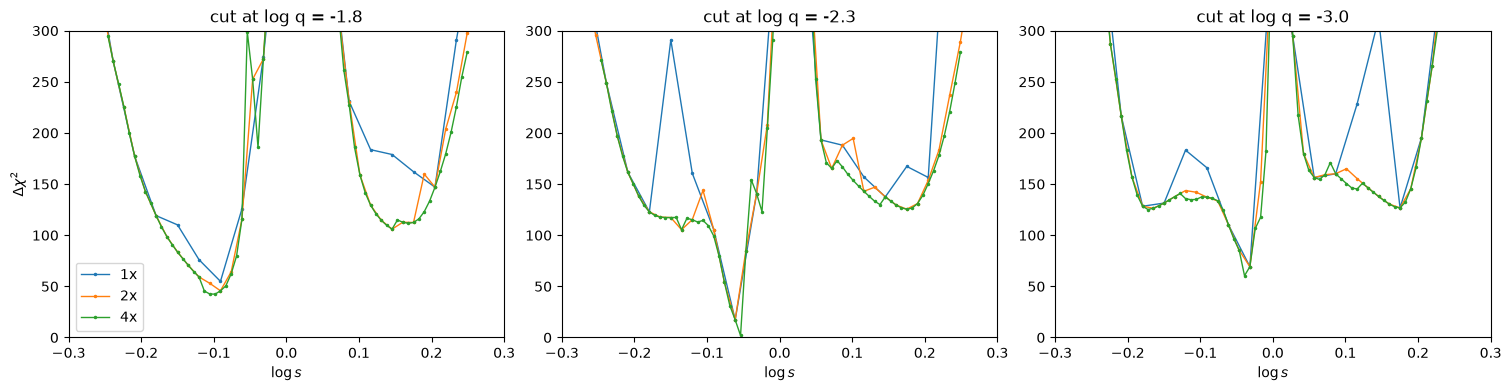

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
for ax, lq in zip(axs, [-1.8, -2.3, -3.0]):
    for name, m in MAPS + [("4x", map4)]:
        j = np.argmin(abs(m["logq"] - lq))
        ax.plot(m["logs"], m["chi2"][:, j] - ref, ".-", ms=3, lw=1, label=name)
    ax.axhline(floor, color="grey", ls=":", lw=1)
    ax.set_xlim(-0.3, 0.3); ax.set_ylim(0, 300); ax.set_xlabel(r"$\log s$"); ax.set_title(f"cut at log q = {lq}")
axs[0].set_ylabel(r"$\Delta\chi^2$"); axs[0].legend()

for name, m in MAPS + [("4x box", map4)]:
    d = m["chi2"] - ref
    S, Q = np.meshgrid(m["logs"], m["logq"], indexing="ij")
    for lev in (10, 40):
        sel = d < lev
        if sel.any():
            print(f"{name:6s}: Delta chi2 < {lev:2d} at {sel.sum():4d} points, log s {S[sel].min():+.3f} .. {S[sel].max():+.3f}, "
                  f"log q {Q[sel].min():+.2f} .. {Q[sel].max():+.2f}")
        else:
            print(f"{name:6s}: Delta chi2 < {lev:2d} at no point")

The cuts show the close valley as a narrow dip whose depth depends on whether a lattice column happens to hit it; the
wide valley is broad and changes little. The region with Δχ² < 40 grows from 9 points at 1× to 35 at 2× and 139 at 4×
(each doubling has four times as many points per area, so from 2× on its area is nearly stable), while Δχ² < 10 is
reached at 2 points at 2× and at 15 at 4×, between log *q* = −2.89 and −2.27. Section 6 shows the valley at a
resolution where the lattice no longer decides its depth.

### 8.2 The floor region is not refined

`densify` refines only points within Δχ² < 500 of the minimum, together with their neighbours (`dchi2_cut=5.0` in
units of 100). The single-lens floor is about 970, so most of the 2× map is left as its first fit found it:

In [12]:
for name, m in MAPS + [("4x box", map4)]:
    d = m["chi2"] - ref
    tE = np.abs(m["pars"][..., 2])
    above = d > (chi2_single - ref) + 1
    print(f"{name:6s}: Delta chi2 > 500 at {100 * (d > 500).mean():3.0f} % of points; above the single-lens floor "
          f"{above.sum():5d} points, at most {d.max() - (chi2_single - ref):7.1f} above it;  tE at the 1000 d bound: "
          f"{100 * (tE > 990).mean():.0f} % of points")

1x    : Delta chi2 > 500 at  80 % of points; above the single-lens floor   734 points, at most  2242.5 above it;  tE at the 1000 d bound: 8 % of points
2x    : Delta chi2 > 500 at  79 % of points; above the single-lens floor  3345 points, at most 10980.8 above it;  tE at the 1000 d bound: 8 % of points
4x box: Delta chi2 > 500 at  11 % of points; above the single-lens floor   170 points, at most  1343.8 above it;  tE at the 1000 d bound: 6 % of points


About four fifths of the 2× map lie more than 500 above the minimum, at large *q* and far from *s* = 1. There a
quarter of the points end above the single-lens floor, some by thousands: failed first fits that the cut kept out of
refinement (the dark specks in the upper part of the 2× map in Section 5). The 1× map, where `lattice` refines every
point, has such points too (about a fifth of them), so the cut is not the only cause: far from the valleys the fits
find no solution as good as a single lens. None of this touches the two valleys.

### 8.3 Cost

The 1× map took 212 minutes for 3420 points: its outlier stage was still improving tens of points per pass when its
limit of 10 passes stopped it. The 2× map took 96 minutes for 13 447 points (outlier passes 1061 → 4 candidates), the
central 4× box 122 minutes for 10 744 points: its neighbour refinement checked 19 966 points and its outlier stage
started with 1221 candidates and ran all 10 passes. Per point, the box was the most expensive, because it holds the
valleys where the work is.

## 9. Summary and using this notebook for your own event

* With the paper's lattice and all defaults, lenscape finds the published solution in a narrow close valley and the
  wide valley of the published V; the shapes match Han et al.'s map, with their Δχ² lower than ours.
* The close valley is narrower than the lattice: its lowest point is 17 above the best fit at 1×, 5.4 at 2× and 1.6
  at 4×. A zoom on the close valley is planned.
* Only the published solution reproduces the brief bump at *t*₁; every alternative loses 20 or more there.
* Points far above the minimum (Δχ² > 500, most of the 2× map) are not refined, and many are worse than the
  single-lens model; they do not affect the valleys.

To run the same steps on another event:

1. Replace the CSV with your photometry, one `(t, flux, flux_err)` triple per data set, with error bars rescaled.
2. Replace `best` with a full fit (`lenscape.fit_full`).
3. Choose the axes of the first lattice.
4. Set `RECOMPUTE = True`, or delete the maps from `data/`.

**References.** Han, C., et al. 2026, arXiv:2601.13450. Yee, J. C., et al. 2012, ApJ, 755, 102.